In [1]:
import os
import json
import random
import shutil
import easyocr
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from ultralytics import YOLO
from transformers import AutoModelForImageTextToText, AutoProcessor

c:\Users\Cristina\miniconda3\envs\VC_P4b\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.is_available())

True


### EasyOCR

In [18]:
plate_detector_960_batch_16_small = YOLO(
    "../P4a/runs/detect/runs_plate/plate_detector_960_BATCH_8_nano/weights/best.pt"
)
plate_detector_960_batch_16_small.to(device)

reader_easy = easyocr.Reader(["es", "en"], gpu=torch.cuda.is_available())


0: 640x480 2 license_plates, 147.5ms
Speed: 2.2ms preprocess, 147.5ms inference, 5.4ms postprocess per image at shape (1, 3, 640, 480)
Results saved to C:\Users\Cristina\Documents\Projects\computer-vision\P4\P4b\runs\detect\predict-4
1 label saved to C:\Users\Cristina\Documents\Projects\computer-vision\P4\P4b\runs\detect\predict-4\labels


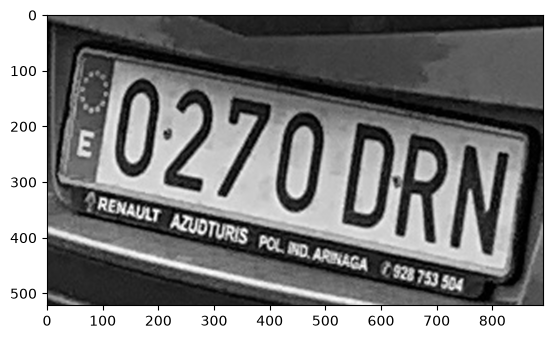

Matrícula detectada: 0270DRN


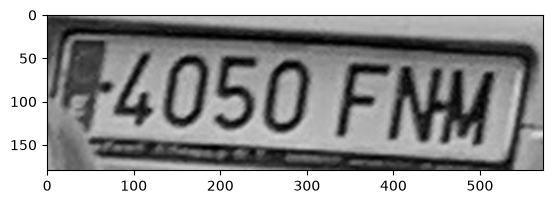

Matrícula detectada: 4050FMM


In [ ]:

img = cv2.imread("../../images-dataset/prac4VC_dataset/images/0270DRN.JPG")

results = plate_detector_960_batch_16_small.predict(source=img, save=True, save_txt=True, conf=0.5, device=device)
for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    pad = 5
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
            max(0, int(x1) - pad) : min(w, int(x2) + pad),
        ].copy() 
    recorte_grande = cv2.resize(
        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)   
    cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
    plt.imshow(cv2.cvtColor(recorte_gris, cv2.COLOR_BGR2RGB))
    plt.show()
    texto = reader_easy.readtext(
    recorte_gris, detail=0, allowlist="0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    )    

    matricula = "No se detectó matrícula válida"
    for t in texto:
        t_limpio = t.replace(" ", "")
        if len(t_limpio) == 7:
            matricula = t_limpio
    print("Matrícula detectada:", matricula)

## Paddle OCR 

In [ ]:
import os
import torch
from transformers import AutoModel, AutoTokenizer

In [ ]:
if not torch.cuda.is_available():
    torch.Tensor.cuda = lambda self, *a, **k: self
    torch.nn.Module.cuda = lambda self, *a, **k: self

In [ ]:
model_name = "baidu/Unlimited-OCR"
path_image = "Test.jpg"
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModel.from_pretrained(
    model_name,
    trust_remote_code=True,
    use_safetensors=True,
    torch_dtype=torch.bfloat16,
)
model = model.eval().cuda()

In [ ]:
model.infer(
    tokenizer,
    prompt="<image>document parsing.",
    image_file=path_image,
    output_path=path_image.replace(".jpg", "_output_Unlimited"),
    base_size=1024,
    image_size=640,
    crop_mode=True,
    max_length=32768,
    no_repeat_ngram_size=35,
    ngram_window=128,
    save_results=True,
)

### SmolVLM


In [5]:
from transformers import AutoModelForImageTextToText, AutoProcessor

# CELDA DE CARGA (ejecutar solo una vez)
processor = AutoProcessor.from_pretrained(
    "HuggingFaceTB/SmolVLM-Instruct",
    )
model_vlm = AutoModelForImageTextToText.from_pretrained(
    "HuggingFaceTB/SmolVLM-Instruct",
    dtype=torch.bfloat16,
    _attn_implementation="eager",
    device_map="cuda",  # carga los pesos directamente en la GPU
)
model_vlm.eval()

Idefics3ForConditionalGeneration(
  (model): Idefics3Model(
    (vision_model): Idefics3VisionTransformer(
      (embeddings): Idefics3VisionEmbeddings(
        (patch_embedding): Conv2d(3, 1152, kernel_size=(14, 14), stride=(14, 14), padding=valid)
        (position_embedding): Embedding(729, 1152)
      )
      (encoder): Idefics3Encoder(
        (layers): ModuleList(
          (0-26): 27 x Idefics3EncoderLayer(
            (self_attn): Idefics3VisionAttention(
              (k_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (v_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (q_proj): Linear(in_features=1152, out_features=1152, bias=True)
              (out_proj): Linear(in_features=1152, out_features=1152, bias=True)
            )
            (layer_norm1): LayerNorm((1152,), eps=1e-06, elementwise_affine=True)
            (mlp): Idefics3VisionMLP(
              (activation_fn): GELUTanh()
              (fc1): Linear(in_feature

In [6]:
print(f"VRAM usada: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM usada: 4.32 GB



0: 640x480 2 license_plates, 11.7ms
Speed: 2.1ms preprocess, 11.7ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 480)


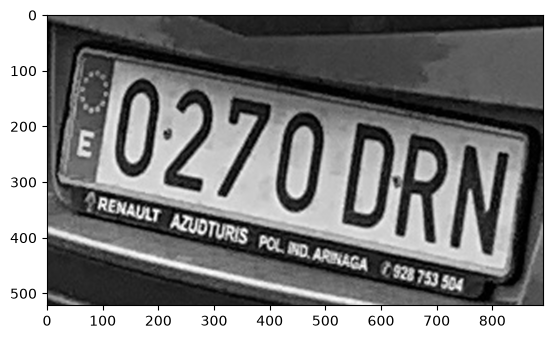

SmolVLM leyó: 0270DRN


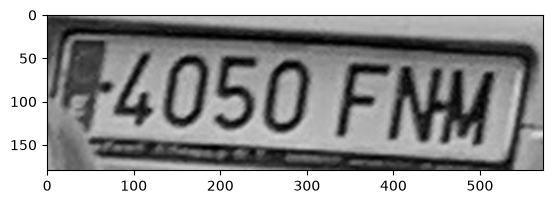

SmolVLM leyó: 4050 FNM


In [8]:
img = cv2.imread("../../images-dataset/prac4VC_dataset/images/0270DRN.JPG")

results = plate_detector_640_batch_8_small.predict(source=img, conf=0.5, device=device)

for box in results[0].boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    pad = 5
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
        max(0, int(x1) - pad) : min(w, int(x2) + pad),
    ].copy()

    recorte_grande = cv2.resize(
        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)
    pil_img = Image.fromarray(cv2.cvtColor(recorte_gris, cv2.COLOR_BGR2RGB))

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {
                    "type": "text",
                    "text": "Read the license plate text in this image. Reply ONLY with the alphanumeric characters of the plate, without spaces or hyphens.",
                },
            ],
        },
    ]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[pil_img], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = model_vlm.generate(**inputs, max_new_tokens=10)
        generated_text = processor.batch_decode(
            generated_ids[:, inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
        )[0]

    plt.imshow(cv2.cvtColor(recorte_gris, cv2.COLOR_BGR2RGB))
    plt.show()
    print("SmolVLM leyó:", generated_text.strip())

In [13]:
import time
import re
from difflib import SequenceMatcher
import pandas as pd


def limpiar_matricula(texto):
    return re.sub(r"[^A-Z0-9]", "", str(texto).upper())


# 1. Cargar el modelo YOLO seleccionado
plate_detector_640_batch_8_small = YOLO(
    "../P4a/runs/detect/runs_plate/plate_detector_640_BATCH_8_small/weights/best.pt"
).to(device)

# 2. Cargar imágenes del dataset junto con sus matrículas reales de los JSON
dataset_dir = Path("../../images-dataset/prac4VC_dataset")
images_dir = dataset_dir / "images"
annotations_dir = dataset_dir / "annotations"

muestras_dataset = []
for img_path in sorted(images_dir.iterdir()):
    if img_path.suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        continue
    json_path = annotations_dir / f"{img_path.stem}.json"
    if not json_path.exists():
        continue

    with open(json_path, "r", encoding="utf-8") as f:
        anotaciones = json.load(f)

    # Extraer matrículas reales válidas (ignorando vacías o placeholders '0000AAA')
    placas_reales = [
        limpiar_matricula(a.get("plate", ""))
        for a in anotaciones
        if limpiar_matricula(a.get("plate", "")) not in ["", "0000AAA"]
    ]

    if len(placas_reales) > 0:
        muestras_dataset.append((img_path, placas_reales))

# Seleccionar un subconjunto fijo de imágenes para evaluar en las mismas condiciones
random.seed(42)
MAX_IMAGENES = 50  # Puedes cambiarlo (ej. 30, 50, 100)
muestras_eval = random.sample(
    muestras_dataset, min(MAX_IMAGENES, len(muestras_dataset))
)

print(
    f"Total imágenes válidas: {len(muestras_dataset)} | Seleccionadas para evaluar: {len(muestras_eval)}"
)

Total imágenes válidas: 212 | Seleccionadas para evaluar: 50


In [10]:
def preprocesar_recorte(img, box, pad=5):
    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
    h, w = img.shape[:2]
    recorte = img[
        max(0, int(y1) - pad) : min(h, int(y2) + pad),
        max(0, int(x1) - pad) : min(w, int(x2) + pad),
    ].copy()
    recorte_grande = cv2.resize(
        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
    )
    recorte_gris = cv2.cvtColor(recorte_grande, cv2.COLOR_BGR2GRAY)
    return recorte_gris


def leer_con_easyocr(recorte_gris):
    t0 = time.perf_counter()
    textos = reader_easy.readtext(
        recorte_gris, detail=0, allowlist="0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    )
    t_inferencia = time.perf_counter() - t0

    candidato = limpiar_matricula("".join(textos))
    for t in textos:
        t_limpio = limpiar_matricula(t)
        if len(t_limpio) == 7:
            candidato = t_limpio
            break
    return candidato, t_inferencia


def leer_con_smolvlm(recorte_gris):
    t0 = time.perf_counter()
    pil_img = Image.fromarray(cv2.cvtColor(recorte_gris, cv2.COLOR_BGR2RGB))
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {
                    "type": "text",
                    "text": "Read the license plate text in this image. Reply ONLY with the alphanumeric characters of the plate, without spaces or hyphens.",
                },
            ],
        }
    ]
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[pil_img], return_tensors="pt").to(device)

    with torch.no_grad():
        generated_ids = model_vlm.generate(**inputs, max_new_tokens=10)
        generated_text = processor.batch_decode(
            generated_ids[:, inputs["input_ids"].shape[1] :],
            skip_special_tokens=True,
        )[0]

    t_inferencia = time.perf_counter() - t0
    return limpiar_matricula(generated_text), t_inferencia


def calcular_metricas_ocr(prediccion, placas_reales):
    if not prediccion:
        return 0, 0.0, ""
    mejor_real = max(
        placas_reales, key=lambda r: SequenceMatcher(None, prediccion, r).ratio()
    )
    similitud = SequenceMatcher(None, prediccion, mejor_real).ratio()
    acierto_exacto = int(prediccion == mejor_real)
    return acierto_exacto, similitud, mejor_real

In [11]:
print("Variable device:", device)
print("Dispositivo de SmolVLM:", next(model_vlm.parameters()).device)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.is_available())
model_vlm = model_vlm.to(device)
print("Dispositivo de SmolVLM:", next(model_vlm.parameters()).device)

Variable device: cuda
Dispositivo de SmolVLM: cuda:0
True
Dispositivo de SmolVLM: cuda:0


In [14]:
resultados_comparativa = []

for idx, (img_path, placas_reales) in enumerate(muestras_eval, 1):
    img = cv2.imread(str(img_path))
    if img is None:
        continue

    # 1. Detectar matrícula con plate_detector_640_batch_8_small
    t0_yolo = time.perf_counter()
    preds_yolo = plate_detector_640_batch_8_small.predict(
        source=img, conf=0.5, verbose=False, device=device
    )
    t_yolo = time.perf_counter() - t0_yolo

    cajas = preds_yolo[0].boxes

    if len(cajas) == 0:
        for nombre_ocr in ["EasyOCR", "SmolVLM"]:
            resultados_comparativa.append(
                {
                    "imagen": img_path.name,
                    "modelo_ocr": nombre_ocr,
                    "matricula_real": placas_reales[0],
                    "prediccion": "",
                    "acierto_exacto": 0,
                    "similitud_caracteres": 0.0,
                    "tiempo_ocr_s": 0.0,
                    "tiempo_total_s": t_yolo,
                }
            )
        continue

    # 2. Evaluar EasyOCR y SmolVLM sobre cada recorte detectado
    for box in cajas:
        recorte_gris = preprocesar_recorte(img, box)

        # --- EasyOCR ---
        pred_easy, t_easy = leer_con_easyocr(recorte_gris)
        exacto_easy, sim_easy, real_easy = calcular_metricas_ocr(
            pred_easy, placas_reales
        )
        resultados_comparativa.append(
            {
                "imagen": img_path.name,
                "modelo_ocr": "EasyOCR",
                "matricula_real": real_easy or placas_reales[0],
                "prediccion": pred_easy,
                "acierto_exacto": exacto_easy,
                "similitud_caracteres": sim_easy,
                "tiempo_ocr_s": t_easy,
                "tiempo_total_s": t_yolo + t_easy,
            }
        )

        # --- SmolVLM ---
        pred_vlm, t_vlm = leer_con_smolvlm(recorte_gris)
        exacto_vlm, sim_vlm, real_vlm = calcular_metricas_ocr(pred_vlm, placas_reales)
        resultados_comparativa.append(
            {
                "imagen": img_path.name,
                "modelo_ocr": "SmolVLM",
                "matricula_real": real_vlm or placas_reales[0],
                "prediccion": pred_vlm,
                "acierto_exacto": exacto_vlm,
                "similitud_caracteres": sim_vlm,
                "tiempo_ocr_s": t_vlm,
                "tiempo_total_s": t_yolo + t_vlm,
            }
        )

    if idx % 10 == 0 or idx == len(muestras_eval):
        print(f"Procesadas {idx}/{len(muestras_eval)} imágenes...")

# Convertir a DataFrame y mostrar tabla resumen comparando EasyOCR vs SmolVLM
df_resultados = pd.DataFrame(resultados_comparativa)

resumen = (
    df_resultados.groupby("modelo_ocr")
    .agg(
        matriculas_evaluadas=("imagen", "count"),
        tasa_acierto_exacto_pct=("acierto_exacto", lambda x: round(x.mean() * 100, 2)),
        similitud_media_pct=(
            "similitud_caracteres",
            lambda x: round(x.mean() * 100, 2),
        ),
        tiempo_medio_ocr_ms=("tiempo_ocr_s", lambda x: round(x.mean() * 1000, 2)),
        tiempo_medio_total_ms=("tiempo_total_s", lambda x: round(x.mean() * 1000, 2)),
    )
    .reset_index()
)

display(resumen)

Procesadas 10/50 imágenes...
Procesadas 20/50 imágenes...
Procesadas 30/50 imágenes...
Procesadas 40/50 imágenes...
Procesadas 50/50 imágenes...


,modelo_ocr,matriculas_evaluadas,tasa_acierto_exacto_pct,similitud_media_pct,tiempo_medio_ocr_ms,tiempo_medio_total_ms
0,EasyOCR,90,25.56,59.72,395.38,415.11
1,SmolVLM,90,43.33,76.89,1516.54,1536.27


In [20]:
from collections import Counter, defaultdict
import cv2
import pandas as pd

csv_entrada = "../P4a/yolo_dual_detections.csv"
video_entrada = "../P4a/plate_test_video.mp4"
video_salida = "yolo_dual_detections_ocr.mp4"
csv_salida = "yolo_dual_detections_ocr.csv"

df = pd.read_csv(csv_entrada)
df["texto_matricula"] = ""

cap = cv2.VideoCapture(video_entrada)
if not cap.isOpened():
    raise RuntimeError(f"No se pudo abrir {video_entrada}")

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

writer = cv2.VideoWriter(
    video_salida, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height)
)

# Agrupar índices del DataFrame por fotograma para acceso O(1)
filas_por_frame = df.groupby("fotograma").groups
lecturas_por_track = defaultdict(Counter)


def consenso_track(counter):
    validas = {k: v for k, v in counter.items() if len(k) >= 4}
    fuente = validas if validas else counter
    return max(fuente.items(), key=lambda x: x[1])[0] if fuente else ""


frame_idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    frame_idx += 1

    for row_idx in filas_por_frame.get(frame_idx, []):
        row = df.loc[row_idx]
        tipo = str(row["tipo_objeto"])

        # Dibujar caja principal (vehículo / persona) si existe
        if pd.notna(row["x1"]) and tipo != "license_plate":
            x1, y1, x2, y2 = (
                int(row["x1"]),
                int(row["y1"]),
                int(row["x2"]),
                int(row["y2"]),
            )
            color = (0, 165, 255) if tipo == "person" else (255, 120, 0)
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            tid_txt = (
                f" ID:{int(row['identificador_tracking'])}"
                if pd.notna(row["identificador_tracking"])
                else ""
            )
            cv2.putText(
                frame,
                f"{tipo}{tid_txt}",
                (x1, max(y1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                color,
                2,
            )

        # Si hay matrícula detectada en esta fila, aplicar OCR
        if row["matrícula_en_su_caso"] == "sí" and pd.notna(row["mx1"]):
            mx1, my1, mx2, my2 = (
                int(row["mx1"]),
                int(row["my1"]),
                int(row["mx2"]),
                int(row["my2"]),
            )
            tid = (
                int(row["identificador_tracking"])
                if pd.notna(row["identificador_tracking"])
                else None
            )

            # Leer con EasyOCR si faltan lecturas para este vehículo o periódicamente
            necesita_ocr = (
                (tid is None)
                or (sum(lecturas_por_track[tid].values()) < 5)
                or (frame_idx % 12 == 0)
            )
            texto_frame = ""
            if necesita_ocr:
                pad = 5
                recorte = frame[
                    max(0, my1 - pad) : min(height, my2 + pad),
                    max(0, mx1 - pad) : min(width, mx2 + pad),
                ]
                if recorte.size > 0 and recorte.shape[0] >= 5 and recorte.shape[1] >= 5:
                    recorte_x3 = cv2.resize(
                        recorte, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC
                    )
                    recorte_gris = cv2.cvtColor(recorte_x3, cv2.COLOR_BGR2GRAY)
                    texto_frame, _ = leer_con_easyocr(recorte_gris)
                    if texto_frame and tid is not None:
                        lecturas_por_track[tid][texto_frame] += 1

            texto_final = (
                consenso_track(lecturas_por_track[tid])
                if tid is not None
                else texto_frame
            )
            df.at[row_idx, "texto_matricula"] = texto_final

            # Dibujar matrícula y texto leído en VERDE
            cv2.rectangle(frame, (mx1, my1), (mx2, my2), (0, 255, 0), 2)
            etiqueta = texto_final if texto_final else "MATRICULA"
            cv2.putText(
                frame,
                etiqueta,
                (mx1, max(my1 - 8, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2,
            )

    writer.write(frame)
    if frame_idx % 100 == 0 or frame_idx == total_frames:
        print(f"Procesados {frame_idx}/{total_frames} fotogramas...")

cap.release()
writer.release()

# Restaurar el nombre original de la segunda columna 'confianza' si pandas la renombró a 'confianza.1'
df.columns = [c.replace(".1", "") if c == "confianza.1" else c for c in df.columns]
df.to_csv(csv_salida, index=False, encoding="utf-8")
print(f"Listo -> Vídeo: {video_salida} | CSV: {csv_salida}")

Procesados 100/2832 fotogramas...
Procesados 200/2832 fotogramas...
Procesados 300/2832 fotogramas...
Procesados 400/2832 fotogramas...
Procesados 500/2832 fotogramas...
Procesados 600/2832 fotogramas...
Procesados 700/2832 fotogramas...
Procesados 800/2832 fotogramas...
Procesados 900/2832 fotogramas...
Procesados 1000/2832 fotogramas...
Procesados 1100/2832 fotogramas...
Procesados 1200/2832 fotogramas...
Procesados 1300/2832 fotogramas...
Procesados 1400/2832 fotogramas...
Procesados 1500/2832 fotogramas...
Procesados 1600/2832 fotogramas...
Procesados 1700/2832 fotogramas...
Procesados 1800/2832 fotogramas...
Procesados 1900/2832 fotogramas...
Procesados 2000/2832 fotogramas...
Procesados 2100/2832 fotogramas...
Procesados 2200/2832 fotogramas...
Procesados 2300/2832 fotogramas...
Procesados 2400/2832 fotogramas...
Procesados 2500/2832 fotogramas...
Procesados 2600/2832 fotogramas...
Procesados 2700/2832 fotogramas...
Procesados 2800/2832 fotogramas...
Procesados 2832/2832 fotogram